# Which food businesses are most at risk of failing a hygiene inspection?
**An analysis of Food Standards Agency hygiene ratings in Leicester and London**

Every restaurant, pub and takeaway in the UK is inspected and given a food hygiene rating from 0 to 5, the "Scores on the Doors" sticker in the window. Having worked front-of-house in restaurants and pubs in both Leicester and London, I wanted to see which kinds of businesses struggle most, and why.

**Questions**
1. What share of food businesses in each area are high risk (rated 0–2)?
2. Which types of business are riskiest: restaurants, pubs, takeaways or others?
3. What's behind low ratings: hygiene, the building, or management?
4. How does Leicester rank against each of London's 33 boroughs?

**Tools:** Python (Pandas, Matplotlib) and SQL (SQLite)

**Data:** [Food Standards Agency open data](https://ratings.food.gov.uk/open-data/), the official published ratings for every food business.

## 1. Load the data

The FSA publishes one file per council. Leicester City is code **878**, and London is split into 33 councils (the 32 boroughs plus the City of London), codes **501–533**. Downloading all 34 files takes a minute or two.

In [10]:
import pandas as pd
import sqlite3
import urllib.request
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

LONDON = {
    "Barking and Dagenham": 501, "Barnet": 502, "Bexley": 503, "Brent": 504,
    "Bromley": 505, "Camden": 506, "Croydon": 507, "City of London": 508,
    "Ealing": 509, "Enfield": 510, "Greenwich": 511, "Hackney": 512,
    "Hammersmith and Fulham": 513, "Haringey": 514, "Harrow": 515, "Havering": 516,
    "Hillingdon": 517, "Hounslow": 518, "Islington": 519, "Kensington and Chelsea": 520,
    "Kingston upon Thames": 521, "Lambeth": 522, "Lewisham": 523, "Merton": 524,
    "Newham": 525, "Redbridge": 526, "Richmond upon Thames": 527, "Southwark": 528,
    "Sutton": 529, "Tower Hamlets": 530, "Waltham Forest": 531, "Wandsworth": 532,
    "Westminster": 533,
}

# (area, council, FSA code)
COUNCILS = [("Leicester", "Leicester", 878)] + [("London", name, code) for name, code in LONDON.items()]

def load_council(area, council, code):
    url = f"https://ratings.food.gov.uk/api/open-data-files/FHRS{code}en-GB.xml"
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    root = ET.fromstring(urllib.request.urlopen(request).read())
    rows = []
    for est in root.iter("EstablishmentDetail"):
        rows.append({
            "area":          area,
            "council":       council,
            "business_name": est.findtext("BusinessName"),
            "business_type": est.findtext("BusinessType"),
            "rating":        est.findtext("RatingValue"),
            "rating_date":   est.findtext("RatingDate"),
            "postcode":      est.findtext("PostCode"),
            "hygiene":       est.findtext("Scores/Hygiene"),
            "structural":    est.findtext("Scores/Structural"),
            "management":    est.findtext("Scores/ConfidenceInManagement"),
        })
    return pd.DataFrame(rows)

raw = pd.concat([load_council(a, c, code) for a, c, code in COUNCILS], ignore_index=True)
print(raw.shape)
raw.head()

(85171, 10)


,area,council,business_name,business_type,rating,rating_date,postcode,hygiene,structural,management
0,Leicester,Leicester,0323 Catering,Other catering premises,5,2025-03-25,None,5,5,5
1,Leicester,Leicester,108 Sweet Street,Other catering premises,5,2021-07-06,None,5,5,5
2,Leicester,Leicester,1313 Tiffin Service,Takeaway/sandwich shop,AwaitingInspection,,None,None,None,None
3,Leicester,Leicester,14Forty At Crown Packaging,Restaurant/Cafe/Canteen,5,2023-09-14,LE3 1TX,0,5,5
4,Leicester,Leicester,2 Brothers Pizza,Takeaway/sandwich shop,4,2026-06-02,LE4 7RP,10,5,5


## 2. Clean the data

- Some businesses are **Exempt** or **Awaiting Inspection**, so they have no 0–5 rating. I remove them.
- I define **high risk** as a rating of **0, 1 or 2**. Under the FSA scheme, 2 means "improvement necessary" and 0 means "urgent improvement necessary".
- The three inspection scores are **penalty points**, so **higher = worse**.


In [11]:
df = raw[raw["rating"].isin(["0", "1", "2", "3", "4", "5"])].copy()
df["rating"] = df["rating"].astype(int)
df["high_risk"] = (df["rating"] <= 2).astype(int)

for col in ["hygiene", "structural", "management"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Removed {len(raw) - len(df)} businesses with no 0–5 rating (exempt or awaiting inspection)")
print(f"{len(df)} rated businesses remain")
df["rating"].value_counts().sort_index()

Removed 10394 businesses with no 0–5 rating (exempt or awaiting inspection)
74777 rated businesses remain


,count
rating,
0,306
1,1758
2,2102
3,6175
4,13003
5,51433


## 3. Q1 – What share of businesses are high risk in Leicester vs London?

In [12]:
conn = sqlite3.connect(":memory:")
df.to_sql("ratings", conn, index=False)

by_area = pd.read_sql("""
    SELECT
        area,
        COUNT(*)                            AS businesses,
        SUM(high_risk)                      AS high_risk_count,
        ROUND(100.0 * SUM(high_risk) / COUNT(*), 1) AS pct_high_risk,
        ROUND(100.0 * SUM(rating = 5) / COUNT(*), 1) AS pct_rated_5
    FROM ratings
    GROUP BY area
""", conn)

by_area

,area,businesses,high_risk_count,pct_high_risk,pct_rated_5
0,Leicester,3141,117,3.7,74.9
1,London,71636,4049,5.7,68.5


## 4. Q2 – Which types of business are riskiest?

In [13]:
by_type = pd.read_sql("""
    SELECT
        business_type,
        COUNT(*) AS businesses,
        ROUND(100.0 * SUM(CASE WHEN area = 'Leicester' THEN high_risk END)
                    / SUM(area = 'Leicester'), 1) AS leicester_pct_high_risk,
        ROUND(100.0 * SUM(CASE WHEN area = 'London' THEN high_risk END)
                    / SUM(area = 'London'), 1)    AS london_pct_high_risk
    FROM ratings
    GROUP BY business_type
    HAVING SUM(area = 'Leicester') >= 20   -- ignore tiny categories
    ORDER BY london_pct_high_risk DESC
""", conn)

by_type

,business_type,businesses,leicester_pct_high_risk,london_pct_high_risk
0,Retailers - other,14444,7.1,9.2
1,Takeaway/sandwich shop,9117,4.5,7.9
2,Restaurant/Cafe/Canteen,26068,3.2,6.0
3,Manufacturers/packers,908,4.4,5.1
4,Pub/bar/nightclub,3858,1.4,3.7
5,Distributors/Transporters,481,4.9,3.4
6,Mobile caterer,2028,0.0,3.3
7,Hotel/bed & breakfast/guest house,972,0.0,3.1
8,Retailers - supermarkets/hypermarkets,2341,2.6,2.5
9,Other catering premises,6417,1.0,2.3


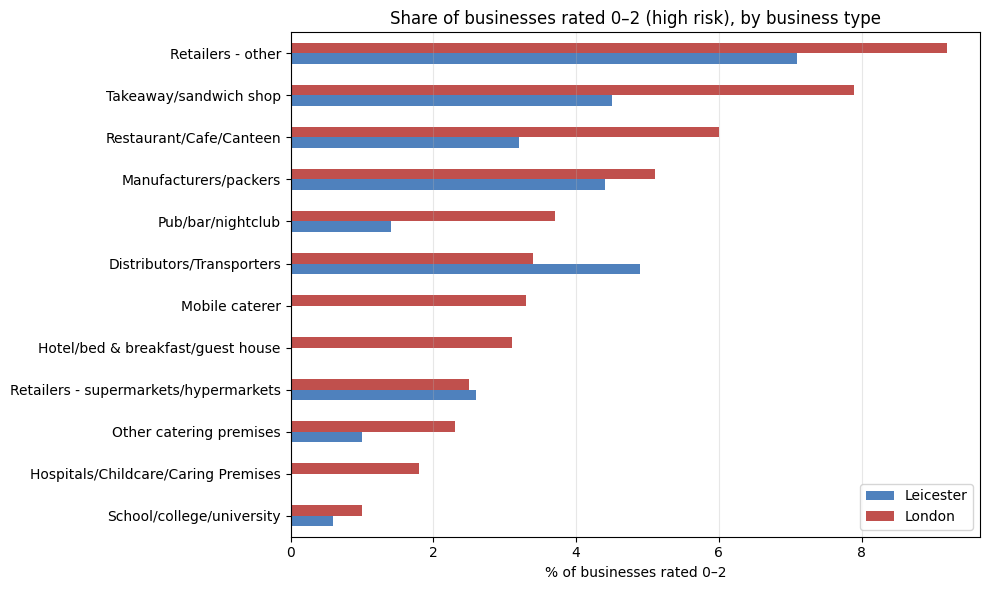

In [14]:
plot = by_type.sort_values("london_pct_high_risk").set_index("business_type")
ax = plot[["leicester_pct_high_risk", "london_pct_high_risk"]].plot(
    kind="barh", figsize=(10, 6), color=["#4f81bd", "#c0504d"])
ax.legend(["Leicester", "London"])
ax.set_ylabel("")
ax.set_title("Share of businesses rated 0–2 (high risk), by business type")
ax.set_xlabel("% of businesses rated 0–2")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("risk_by_type.png", dpi=150)
plt.show()

## 5. Q3 – What's behind low ratings?

Inspectors score three things, in penalty points (higher = worse):
- **Hygiene:** how food is handled, stored and cooked
- **Structural:** cleanliness and condition of the building, layout, pest control
- **Confidence in management:** training, records and food safety procedures

I compared the average scores of high-risk businesses with everyone else.

In [15]:
drivers = pd.read_sql("""
    SELECT
        CASE WHEN high_risk = 1 THEN 'High risk (0–2)' ELSE 'Rated 3–5' END AS grp,
        ROUND(AVG(hygiene), 1)    AS avg_hygiene,
        ROUND(AVG(structural), 1) AS avg_structural,
        ROUND(AVG(management), 1) AS avg_management
    FROM ratings
    WHERE hygiene IS NOT NULL
    GROUP BY grp
""", conn).set_index("grp")

drivers

,avg_hygiene,avg_structural,avg_management
grp,,,
High risk (0–2),10.8,13.5,14.8
Rated 3–5,3.2,4.0,4.1


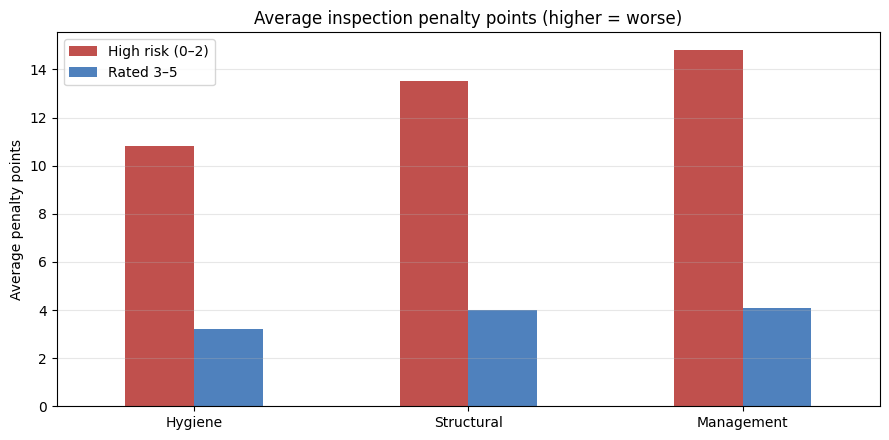

How many more penalty points high-risk businesses get, on average:
avg_management    10.7
avg_structural     9.5
avg_hygiene        7.6
dtype: float64


In [16]:
ax = drivers.T.plot(kind="bar", figsize=(9, 4.5), color=["#c0504d", "#4f81bd"], rot=0)
ax.set_title("Average inspection penalty points (higher = worse)")
ax.set_xticklabels(["Hygiene", "Structural", "Management"])
ax.set_ylabel("Average penalty points")
ax.legend(title="")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("risk_drivers.png", dpi=150)
plt.show()

gap = drivers.loc["High risk (0–2)"] - drivers.loc["Rated 3–5"]
print("How many more penalty points high-risk businesses get, on average:")
print(gap.sort_values(ascending=False))

## 6. Q4 – How does Leicester rank against each London borough?

In [17]:
by_council = pd.read_sql("""
    SELECT
        council,
        area,
        COUNT(*)                                    AS businesses,
        ROUND(100.0 * SUM(high_risk) / COUNT(*), 1) AS pct_high_risk,
        RANK() OVER (ORDER BY 1.0 * SUM(high_risk) / COUNT(*) DESC) AS risk_rank
    FROM ratings
    GROUP BY council, area
    ORDER BY risk_rank
""", conn)

leicester_rank = by_council.loc[by_council["council"] == "Leicester", "risk_rank"].iloc[0]
print(f"Leicester ranks {leicester_rank} out of {len(by_council)} councils (1 = highest share of high-risk businesses)")
by_council

Leicester ranks 19 out of 34 councils (1 = highest share of high-risk businesses)


,council,area,businesses,pct_high_risk,risk_rank
0,Newham,London,2440,13.9,1
1,Ealing,London,3179,13.1,2
2,Waltham Forest,London,1862,12.2,3
3,Enfield,London,2148,9.3,4
4,Barking and Dagenham,London,1235,7.9,5
5,Camden,London,3355,7.9,6
6,Hillingdon,London,2008,7.7,7
7,Redbridge,London,1827,7.3,8
8,Westminster,London,5317,6.5,9
9,Lambeth,London,2445,6.5,10


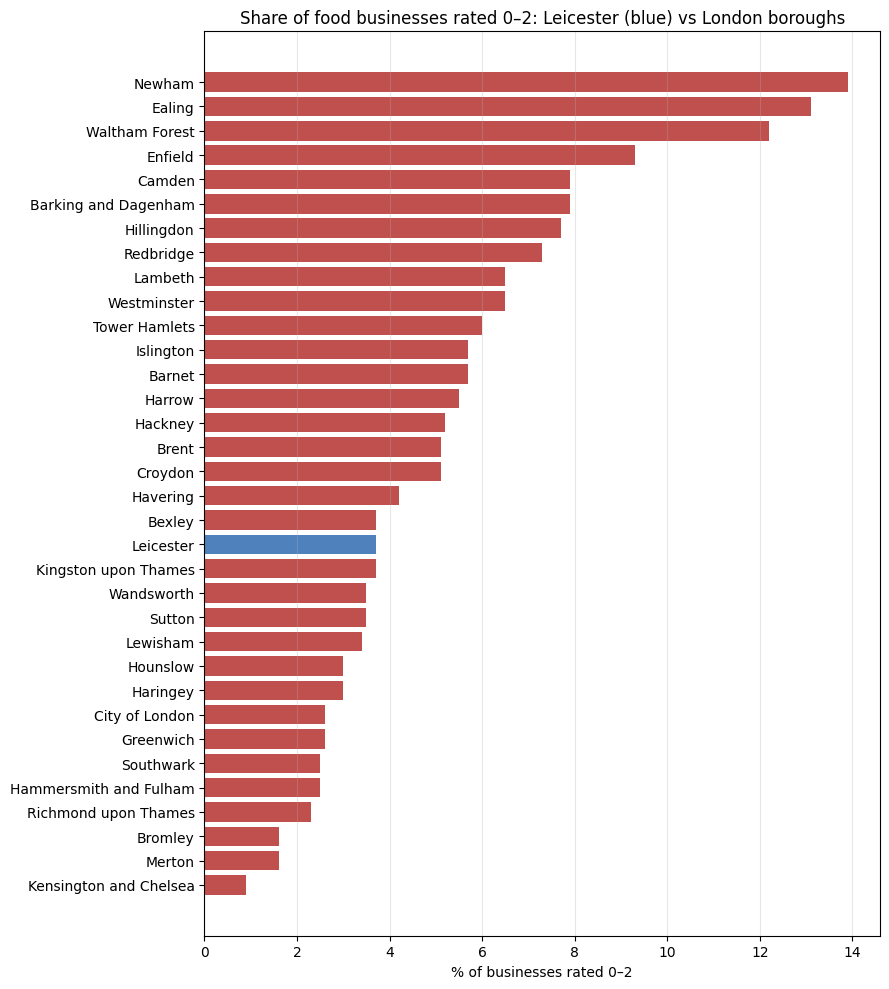

In [18]:
plot = by_council.sort_values("pct_high_risk")
colours = ["#4f81bd" if a == "Leicester" else "#c0504d" for a in plot["area"]]
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(plot["council"], plot["pct_high_risk"], color=colours)
ax.set_title("Share of food businesses rated 0–2: Leicester (blue) vs London boroughs")
ax.set_xlabel("% of businesses rated 0–2")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("risk_by_council.png", dpi=150)
plt.show()

In [ ]:
## 7. Findings

- **London is riskier than Leicester overall.** 5.7% of rated food businesses in London are high risk (rated 0–2), compared with 3.7% in Leicester. Leicester also has more businesses with the top rating of 5 (74.9% vs 68.5%).
- **Takeaways and small shops are the riskiest types; pubs are among the safest.** Small retailers (7.1% Leicester, 9.2% London) and takeaways (4.5% vs 7.9%) have the highest share of high-risk ratings. Pubs, bars and nightclubs are much lower (1.4% in Leicester, 3.7% in London).
- **London is worse in almost every category.** For takeaways, restaurants and pubs, London's high-risk share is roughly 1.7–2.6 times Leicester's.
- **Management is the biggest driver of low ratings.** High-risk businesses average 14.8 penalty points for confidence in management, compared with 4.1 for everyone else (a gap of 10.7). The gap is 9.5 points for structural issues and 7.6 for food hygiene.
- **Location matters more than the city.** Leicester ranks 19th out of 34 councils, in the middle of the London boroughs. But London varies hugely: Newham (13.9%), Ealing (13.1%) and Waltham Forest (12.2%) have over ten times the high-risk share of Kensington and Chelsea (under 1%).

## 8. Recommendations

- **For restaurant and pub operators:** since management scores drive low ratings most, focus on staff food safety training, keeping records up to date and running regular self-checks before inspections. These are cheaper to fix than building issues.
- **For councils:** target inspection time at takeaways and small retailers, and at the boroughs where high-risk businesses are concentrated, such as Newham, Ealing and Waltham Forest.
- **For delivery platforms and customers:** takeaways carry above-average risk, so showing hygiene ratings clearly on delivery apps would help customers make informed choices.

## Limitations and next steps
- Ratings reflect the last inspection, which may be several years old for some businesses.
- The three scores use different scales (management goes up to 30 points, hygiene and structural up to 25), so the gaps are a guide rather than an exact like-for-like comparison.
- Only 5.6% of rated businesses are high risk overall, so some smaller Leicester categories should be read with care.
- Next step: check whether high-risk businesses are re-inspected quickly.